# 03 — Keşifsel Veri Analizi (EDA)

Girdi: `data/processed/arac_temiz_v3.csv`.

Araştırma sorularına bağlı bulgular burada toplanır: (1) etkenler, (3) yaş–fiyat profili, (4) şehir. Şehir analizi ve yaş–fiyat profili henüz eksik.


In [8]:
import pandas as pd

# v3 verisini yükle (notebooks klasöründen bir üst dizine çıkılarak)
v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")

print("--- HİBRİT/ELEKTRİK 'EV' KONTROLÜ ---")
he = v3[v3["yakit_turu"].isin(["Hibrit", "Elektrik"])]
sus = he[~he["variant"].str.upper().str.contains(r"\bEV\b|HYBRID|HIBRIT|ELECTRIC|E-TRON|EQ", regex=True, na=False)]
print(f"Şüpheli (Yanlış Etiketlenmiş) Kayıt Sayısı: {len(sus)}")
if len(sus) > 0:
    print(sus["variant"].value_counts().head(20))

print("\n--- BİLİNMİYOR YAKIT ÖRNEKLEMİ (40 ADET) ---")
bil = v3[v3["yakit_turu"] == "Bilinmiyor"]
if len(bil) > 0:
    print(bil[["brand", "model", "variant"]].sample(min(40, len(bil)), random_state=7))

print("\n--- ŞEHİR VE RENK DAĞILIMI ---")
print(f"Benzersiz Şehir Sayısı: {v3['city'].nunique()}")
print("Şehir Listesi:", sorted(v3["city"].dropna().unique()))
print("\nRenk Dağılımı:")
print(v3["color"].value_counts())

--- HİBRİT/ELEKTRİK 'EV' KONTROLÜ ---
Şüpheli (Yanlış Etiketlenmiş) Kayıt Sayısı: 1530
variant
1.0 TCe Evolution           1057
EVO 1.3 Multijet Dynamic     131
EVO 1.4 Dynamic               82
1.5 Mhev Premium              60
1.4 Fever                     45
1.5 Mhev Elite                32
EVO 1.4 Fire Active           29
EVO 1.4 Fire My Life          27
EVO 1.3 Multijet Active       26
EVO 1.4 Multiair Dynamic      17
EVO 1.3 Multijet My Life      15
EVO 1.4 Fire Dynamic           9
Name: count, dtype: int64

--- BİLİNMİYOR YAKIT ÖRNEKLEMİ (40 ADET) ---
            brand    model                     variant
175103    renault   megane                 1.3 TCe Joy
20283         bmw        3  320i First Edition M Sport
122671       opel    astra                 1.6 Edition
72011        ford    focus                    1.6 Ghia
118309     nissan    micra                   1.2 Match
30891   chevrolet    cruze              1.6 Sport Plus
43619        fiat     egea         1.6 Multijet Loun

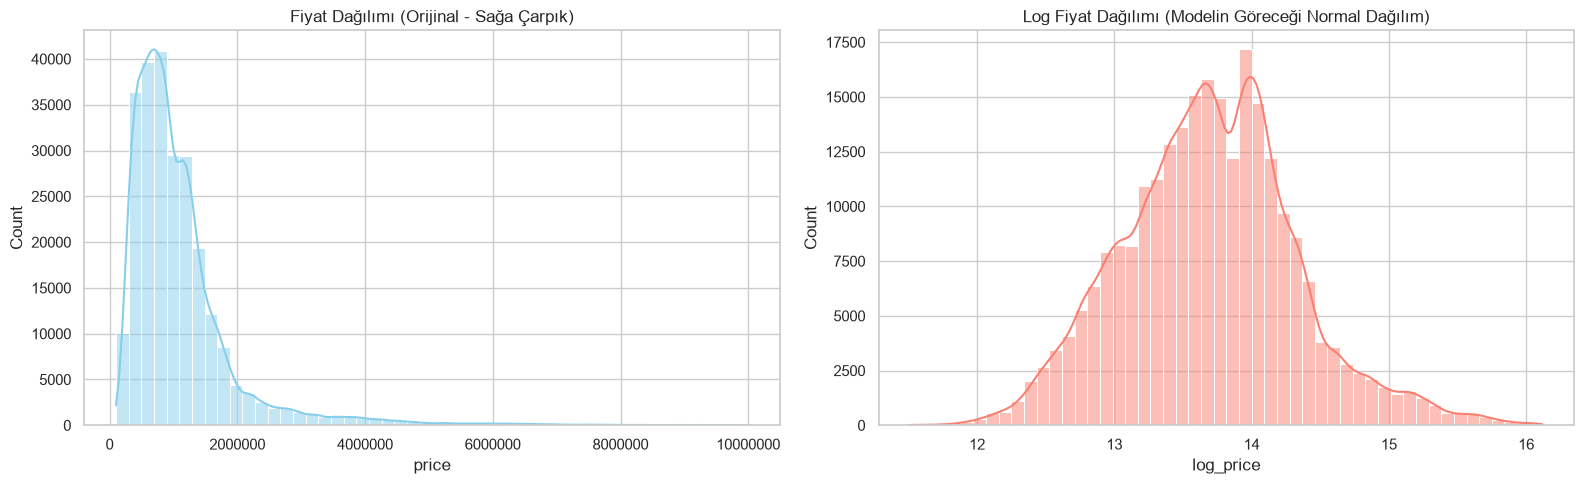

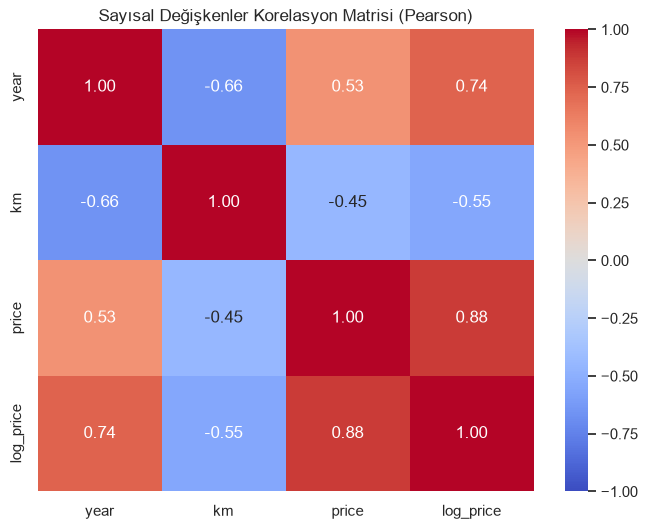

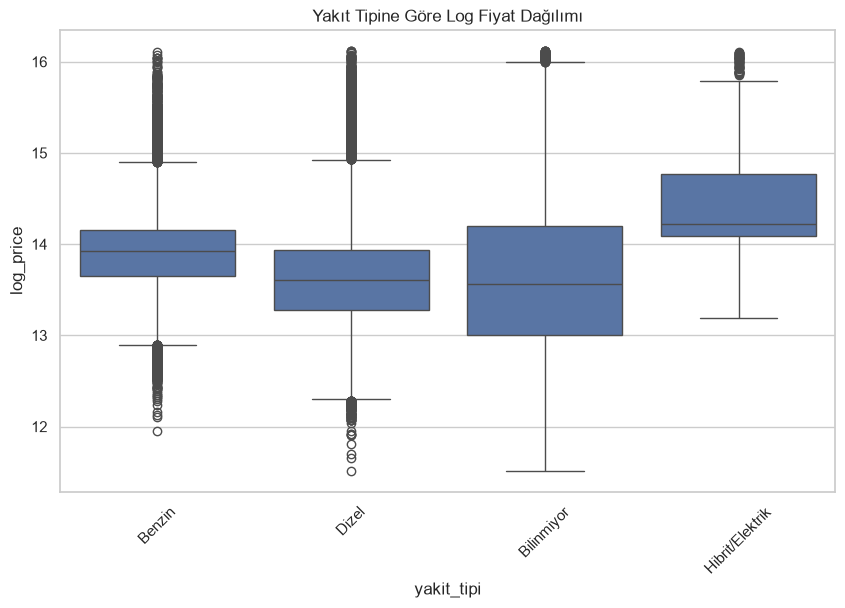

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Temizlenmiş veriyi yükle (Notebook içinden çalıştırıldığı için ../ kullanıldı)
df = pd.read_csv("../data/processed/arac_temiz_v3.csv")

# 1. Hedef Değişken (Fiyat) Dağılımı Orijinal vs Logaritmik
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df['price'], bins=50, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Fiyat Dağılımı (Orijinal - Sağa Çarpık)')
axes[0].ticklabel_format(style='plain', axis='x')

sns.histplot(df['log_price'], bins=50, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Log Fiyat Dağılımı (Modelin Göreceği Normal Dağılım)')
plt.tight_layout()
plt.show()

# 2. Sayısal Değişkenlerin Korelasyon Matrisi
num_cols = ['year', 'km', 'price', 'log_price']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Sayısal Değişkenler Korelasyon Matrisi (Pearson)')
plt.show()

# 3. Yakıt Tipine Göre Fiyat Dağılımı (Kutu Grafiği)
plt.figure(figsize=(10, 6))
sns.boxplot(x='yakit_tipi', y='log_price', data=df)
plt.title('Yakıt Tipine Göre Log Fiyat Dağılımı')
plt.xticks(rotation=45)
plt.show()